In [156]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis, plot_predictive_density_simple, plot_bimodality_and_series_2, plot_predictive_density_ax
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [157]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import target series and detrend series with HP filter  + linear trend of the volatility scaling

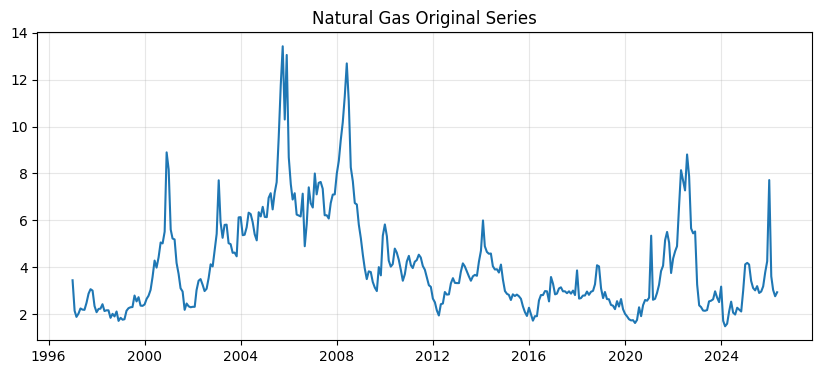

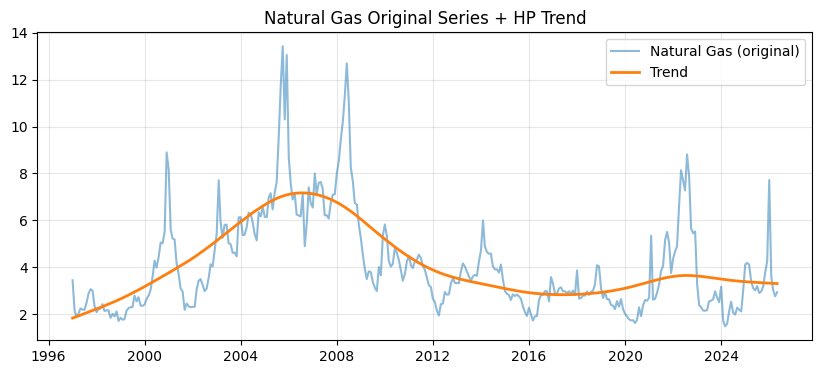

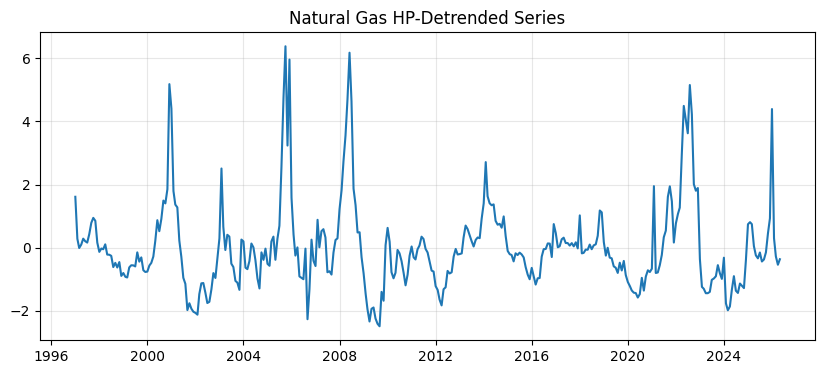

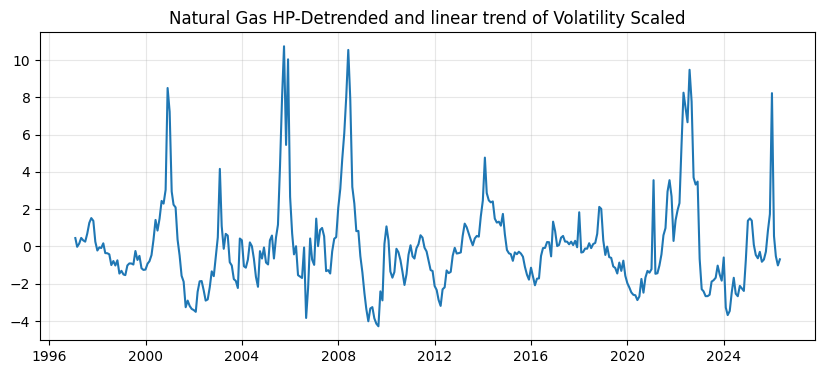

In [158]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend


gas_diff = (df_ngas["gas_cycle"]).diff().dropna()
gas_sigma = linear_vol_scale(gas_diff)


df_ngas["gas_scaled_cycle"]= df_ngas["gas_cycle"]/gas_sigma

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()

# Plot cycle Scaled
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_scaled_cycle"])
plt.title("Natural Gas HP-Detrended and linear trend of Volatility Scaled")
plt.grid(True, alpha=0.3)
plt.show()



### Extract Data for Exogeous Variables

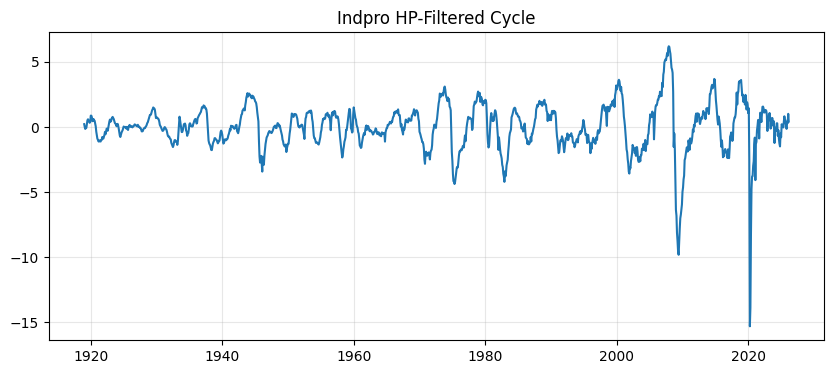

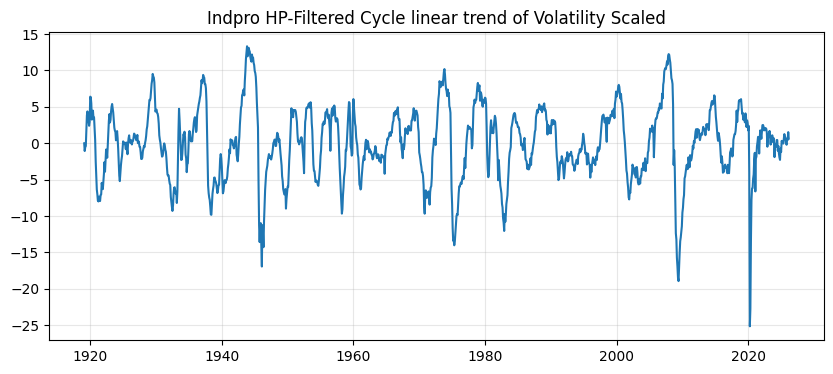

In [159]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle linear trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

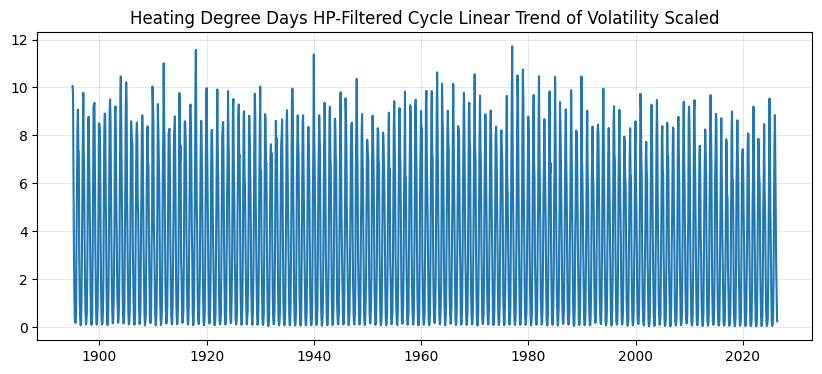

In [160]:
# -------------------------
# Heating Degree Days
# -------------------------
df_hdd = pd.read_csv(
    "HDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_hdd = df_hdd.set_index("Date").dropna()


hdd=0.01*df_hdd

plt.figure(figsize=(10,4))
plt.plot(hdd)
plt.title("Heating Degree Days HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_28056/389981700.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


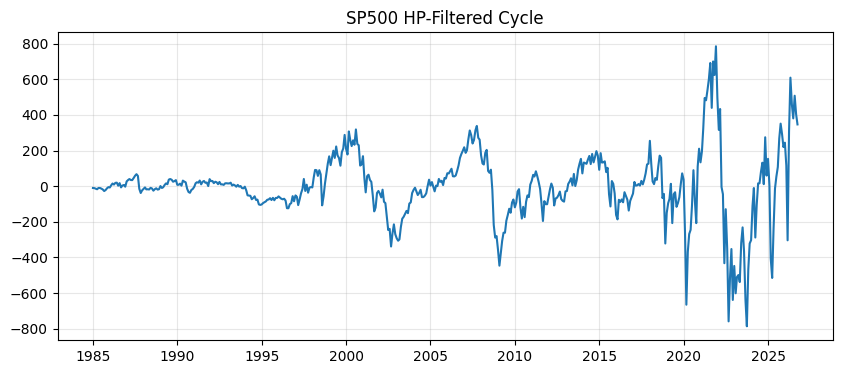

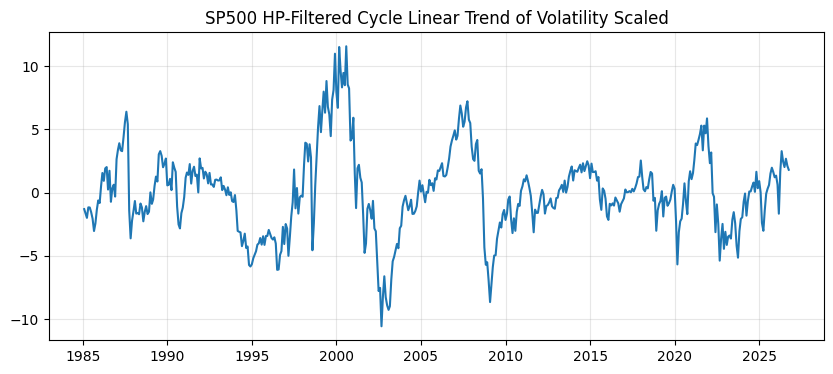

In [161]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [162]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_scaled_cycle"], indpro, hdd, sp500
    ],
    axis=1
).dropna()

df.columns = ["gas_scaled_cycle", "indpro",  "hdd", "sp500"]
df = df.sort_index()

start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["gas_scaled_cycle"].values
X = df[[  "indpro", "hdd", "sp500"]].values

var = ["indpro",  "hdd", "sp500"]

t1=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01

y_limits=(-10, 15)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [163]:
#import PSY pickle

with open("psy_ngas.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -499.50269554935034

Estimated parameters:
phi             =     0.2449 (0.0262)
psi             =     0.8005 (0.0219)
sigma           =     0.4236 (0.0304)

Hessian condition number:
2.3192479262319137

Eigenvalues of Hessian:
[2472.9100677  1345.91640963 1066.25515959]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -499.502696
AIC:            1005.005391
BIC:            1016.561999
R^2:            0.682785

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 15.882478, p-value = 6.73998e-05
    lag  5: statistic = 28.527135, p-value = 2.87041e-05
    lag 10: statistic = 39.253775, p-value = 2.29175e-05
    lag 20: statistic = 44.511214, p-value = 0.00128481

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 24.323731, p-value = 8.14297e-07
    la

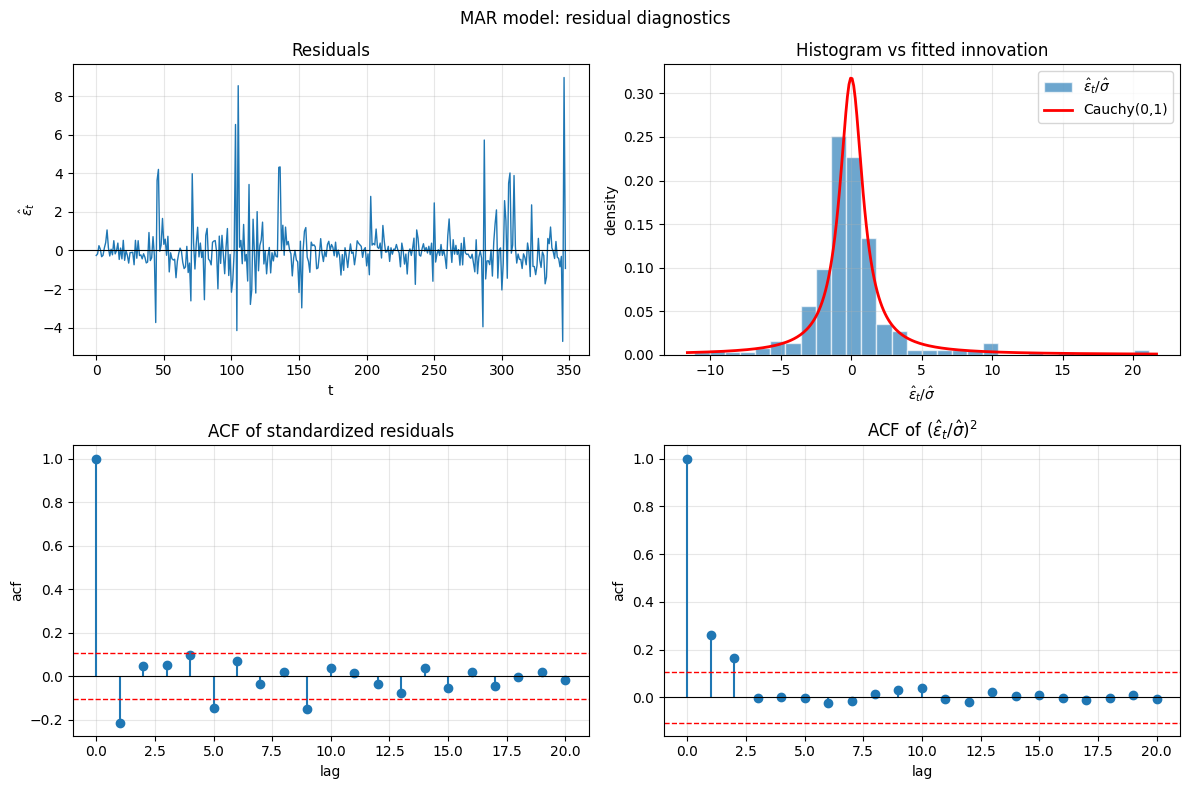

In [164]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

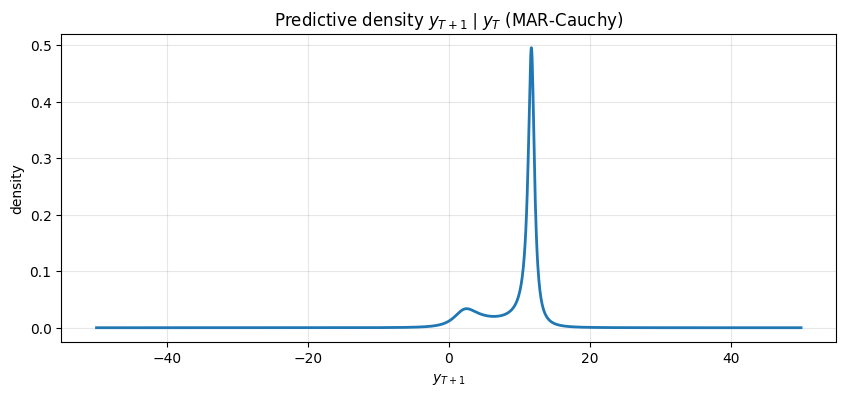

In [165]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

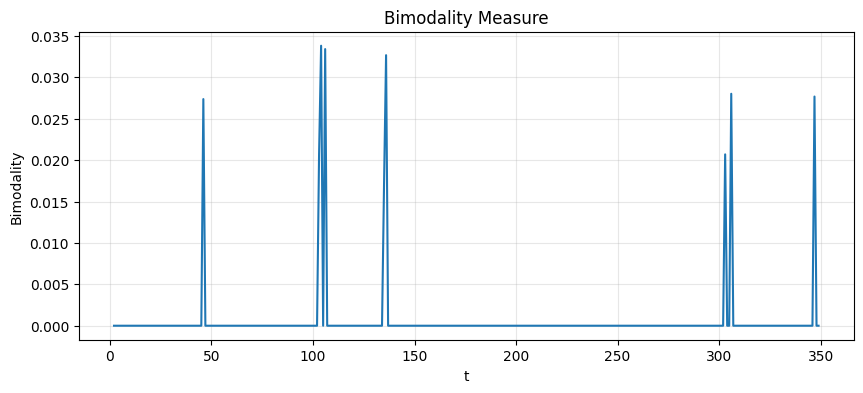

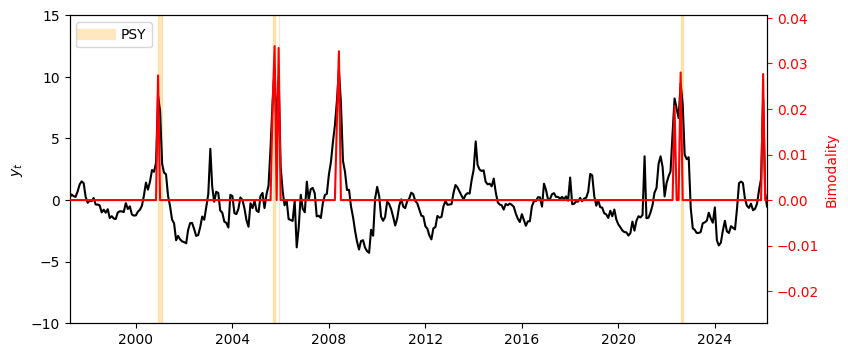

In [166]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


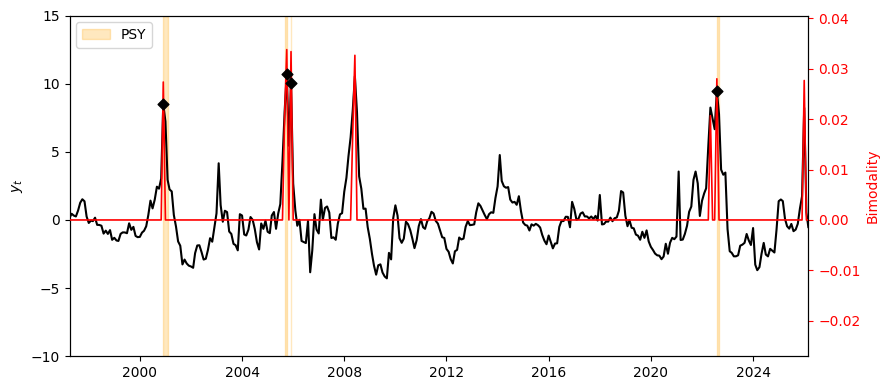

In [167]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 44, 102, 104, 304] 
)

### Look at Predictive Density at points of interest

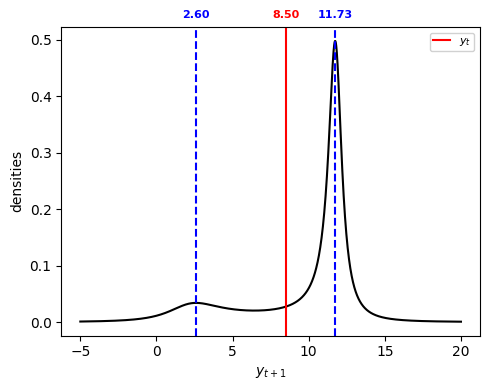

In [168]:
t0 = 46

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

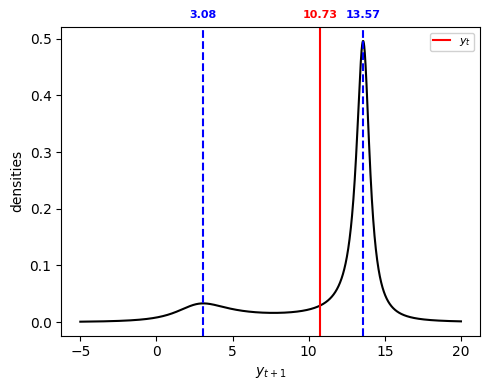

In [169]:
t0 = 104

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

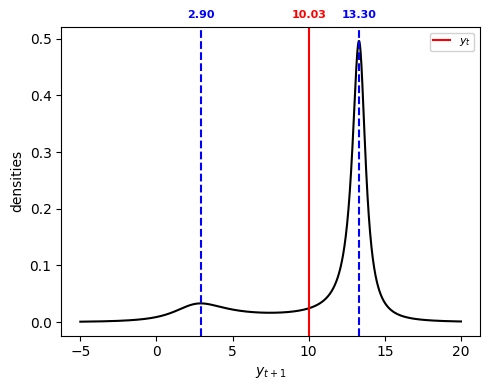

In [170]:
t0 = 106

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

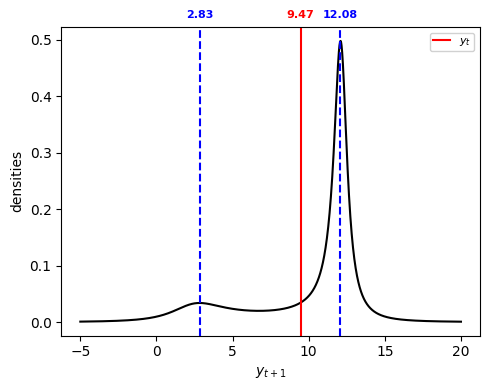

In [171]:
t0 = 306

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params   
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -491.6078879197762

Estimated parameters:
phi             =     0.2459 (0.0312)
psi             =     0.7831 (0.0220)
beta_indpro     =     0.0177 (0.0072)
beta_hdd        =    -0.0221 (0.0077)
beta_sp500      =    -0.0245 (0.0114)
sigma           =     0.4015 (0.0297)

Hessian condition number:
48.449876459221414

Eigenvalues of Hessian:
[45528.38544429 19677.29236027  6853.29058859  2377.93154602
   939.70075409  1139.09505846]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -491.607888
AIC:            995.215776
BIC:            1018.328991
R^2:            0.682485

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 14.617802, p-value = 0.000131665
    lag  5: statistic = 27.096188, p-value = 5.46341e-05
    lag 10: statistic = 37.652315, p-value = 4.36204e-05
    lag 20: statistic = 42.411497, p-value = 0.00244346

Autocorrelation tests (

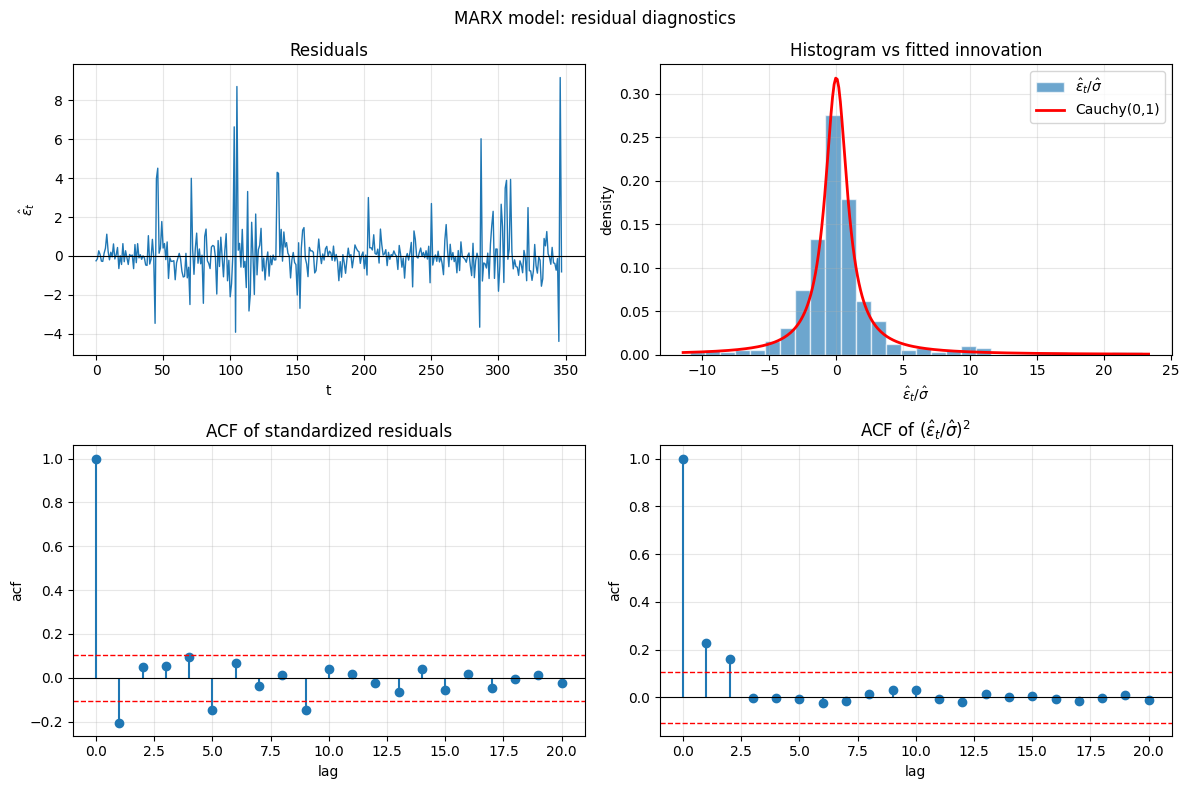

In [172]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_indpro", "beta_hdd", "beta_sp500", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

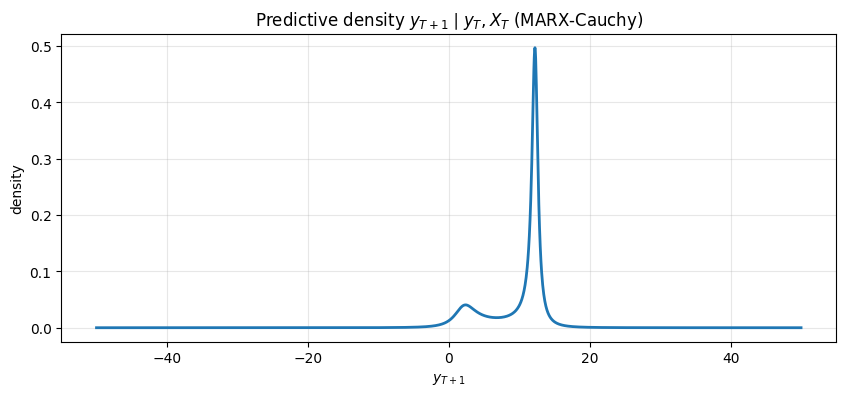

In [173]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

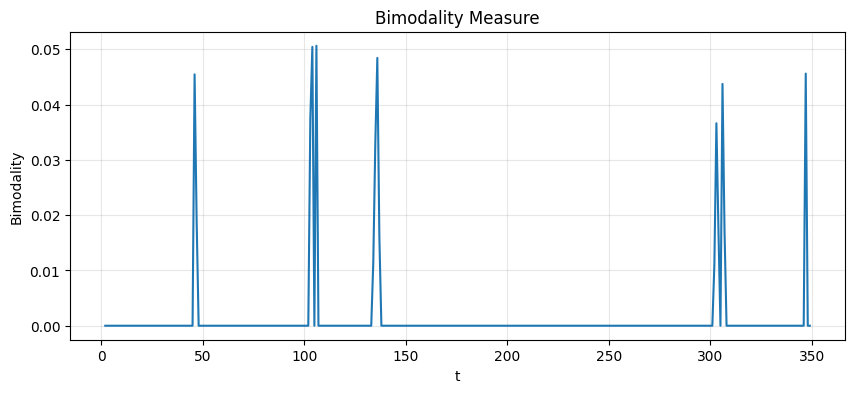

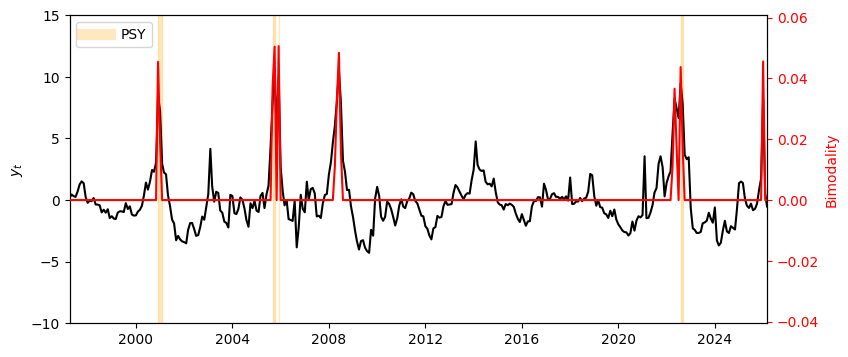

In [174]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


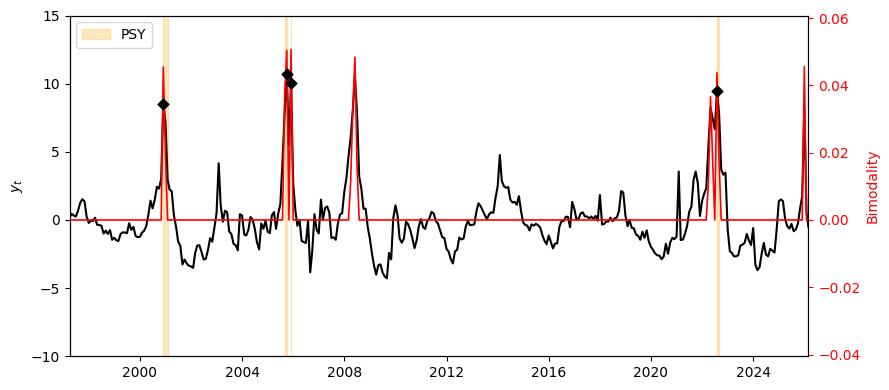

In [175]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 44, 102, 104, 304]
)

### Look at Predictive Density at points of interest

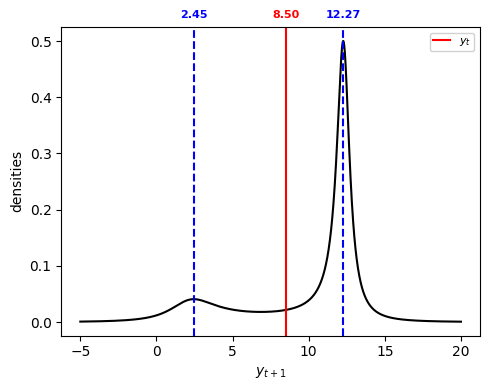

In [176]:
t0 = 46

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

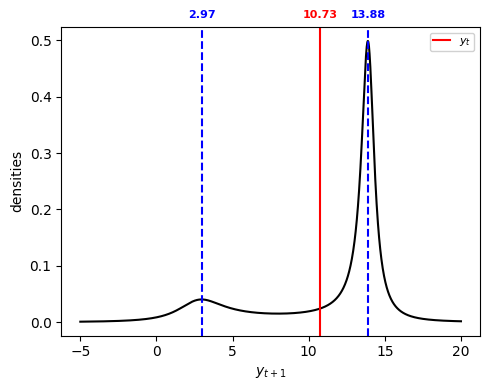

In [177]:
t0 = 104

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

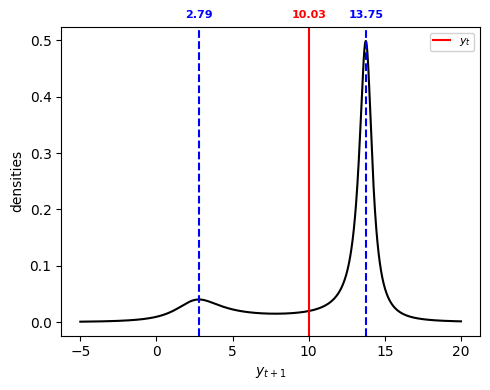

In [178]:
t0 = 106

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

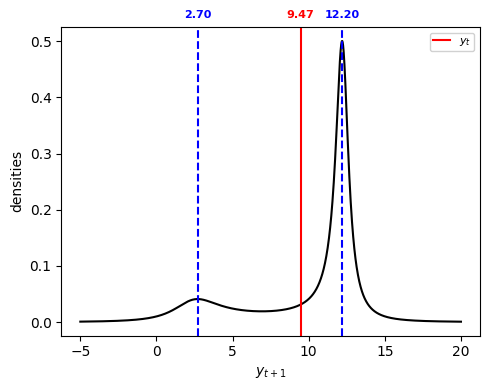

In [179]:
t0 = 306

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params   
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

### Look at Predictive Density at and around all points where bimodality is not 0

Bimodal times:
[ 46  47 103 104 106 134 135 136 137 302 303 304 306 307 347]


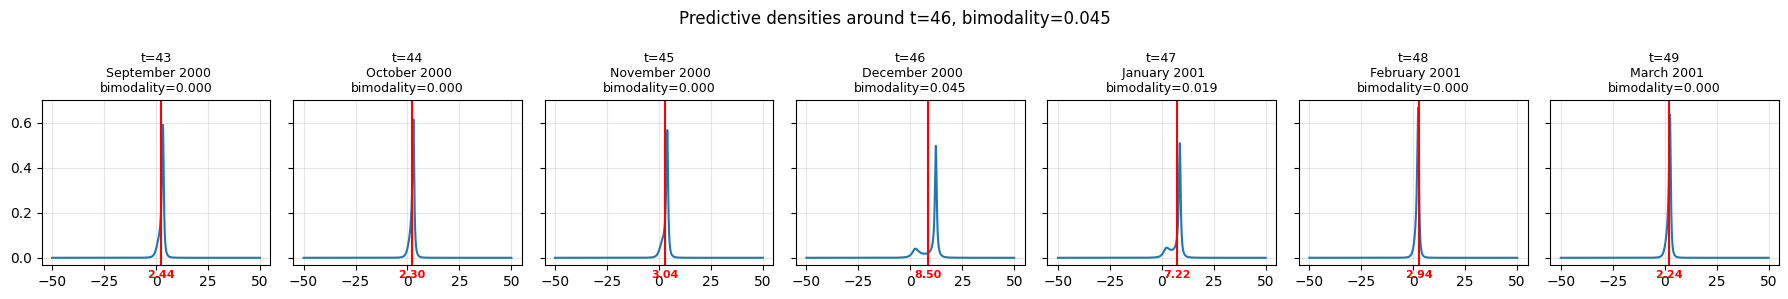

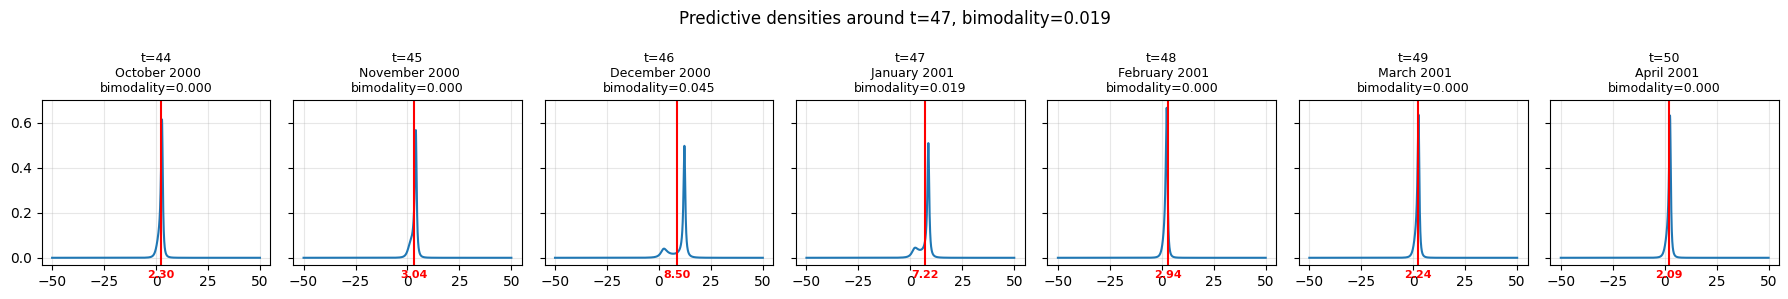

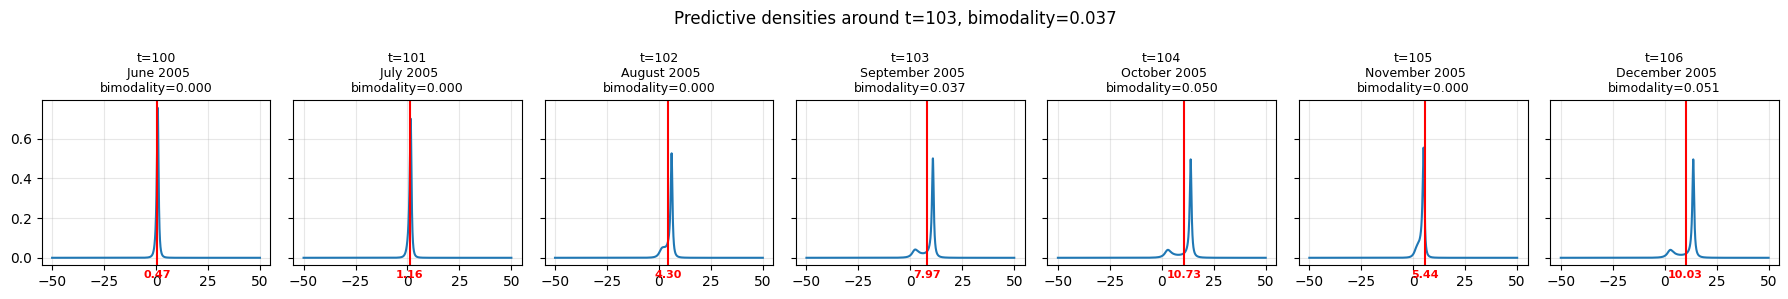

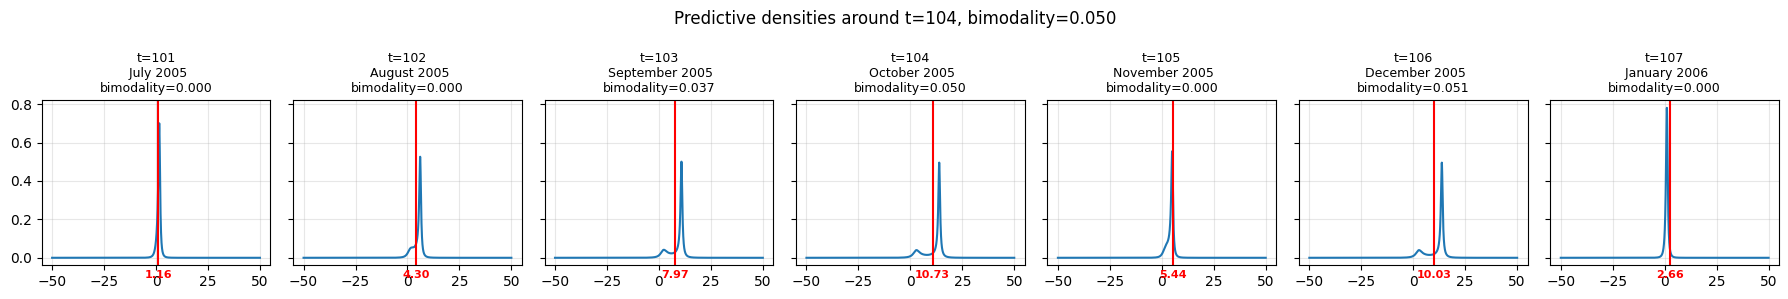

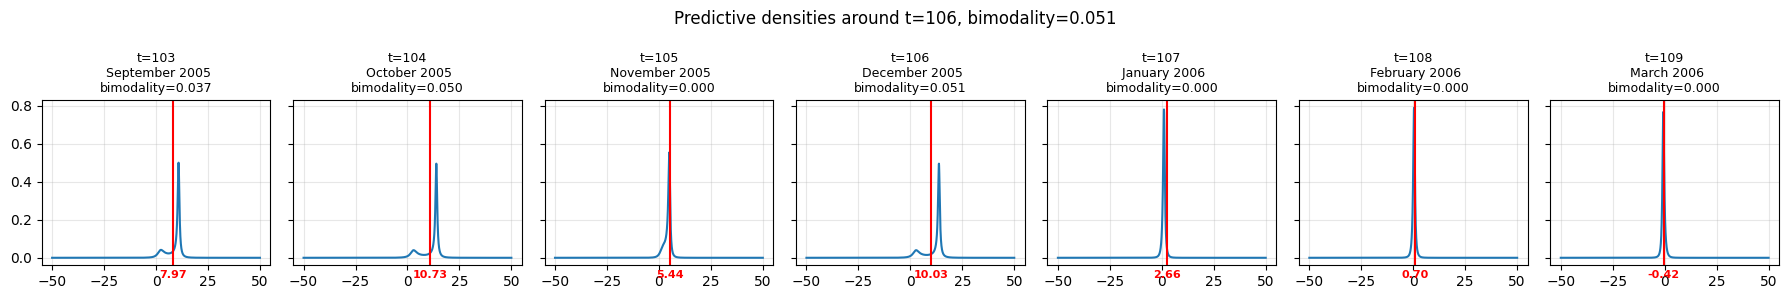

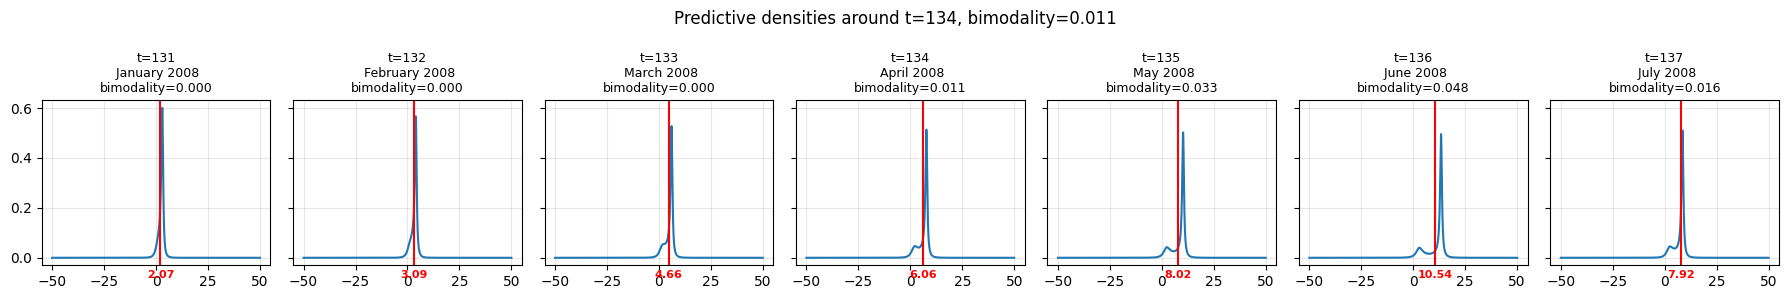

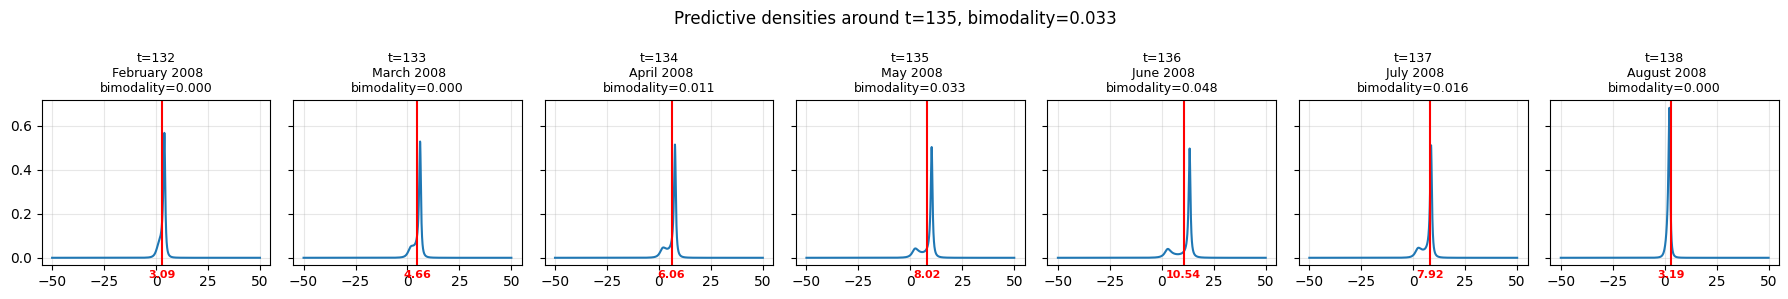

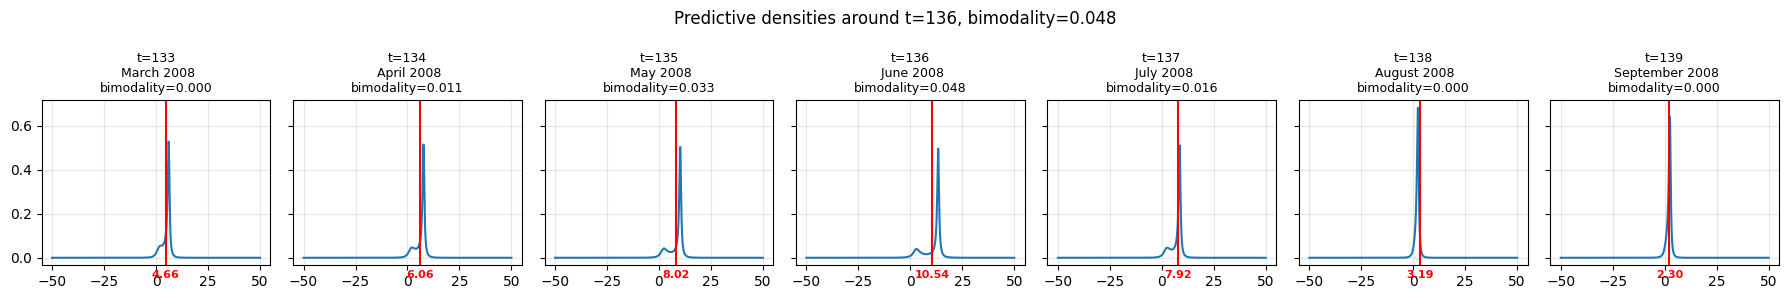

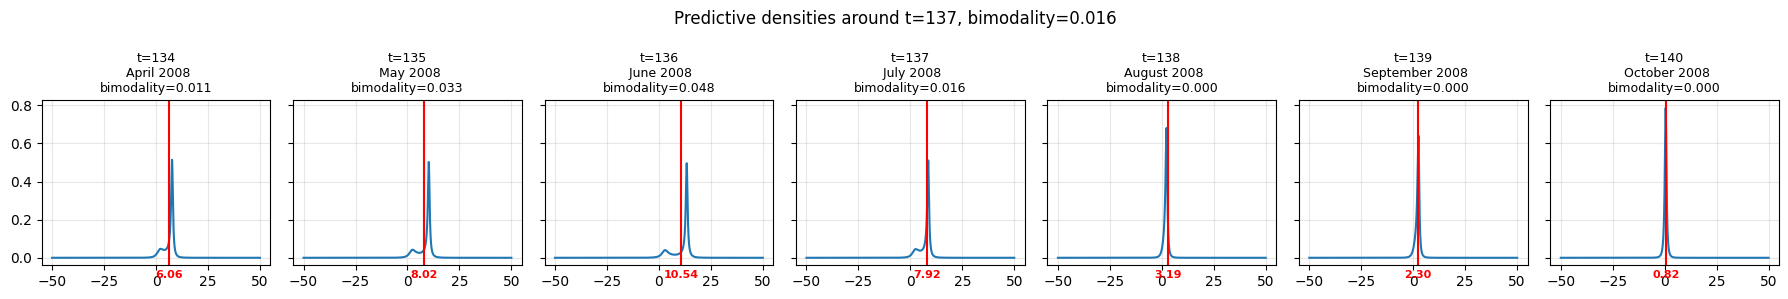

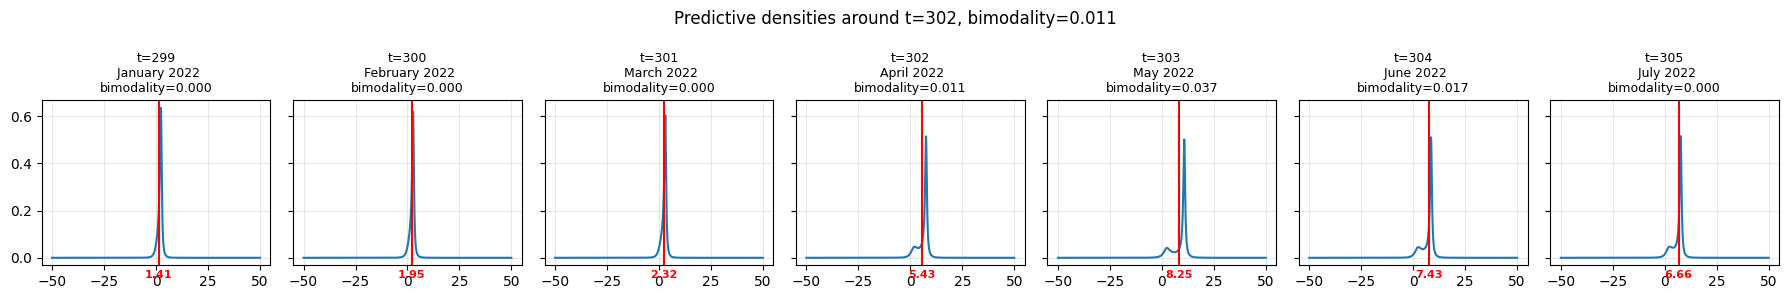

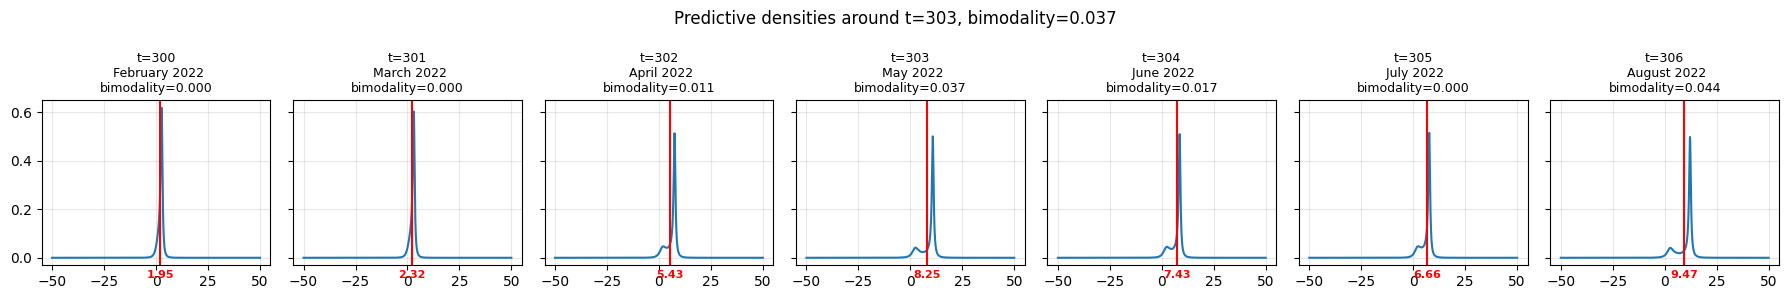

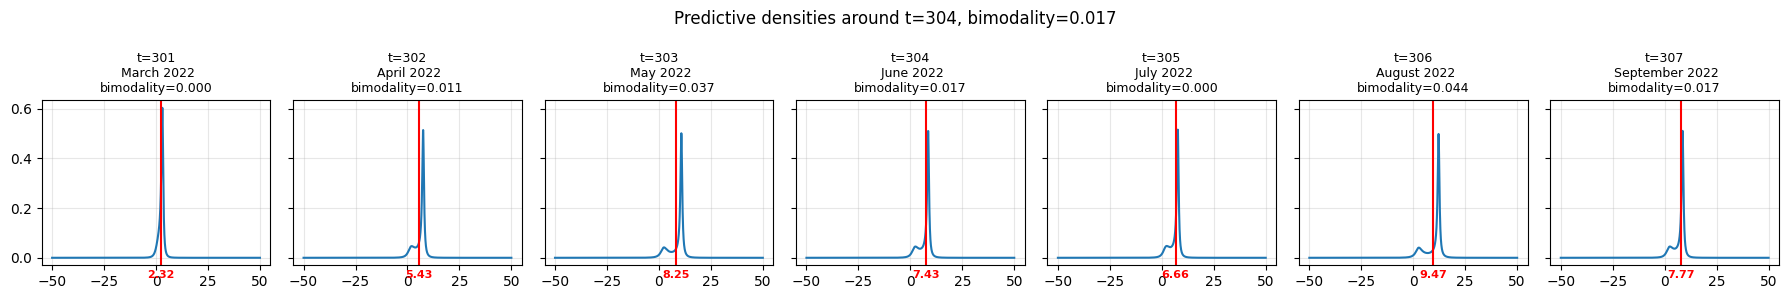

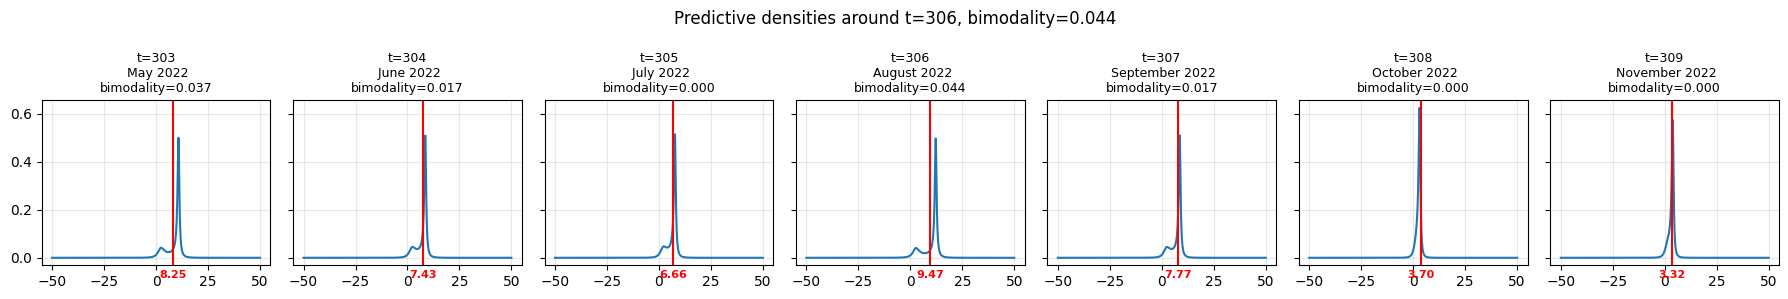

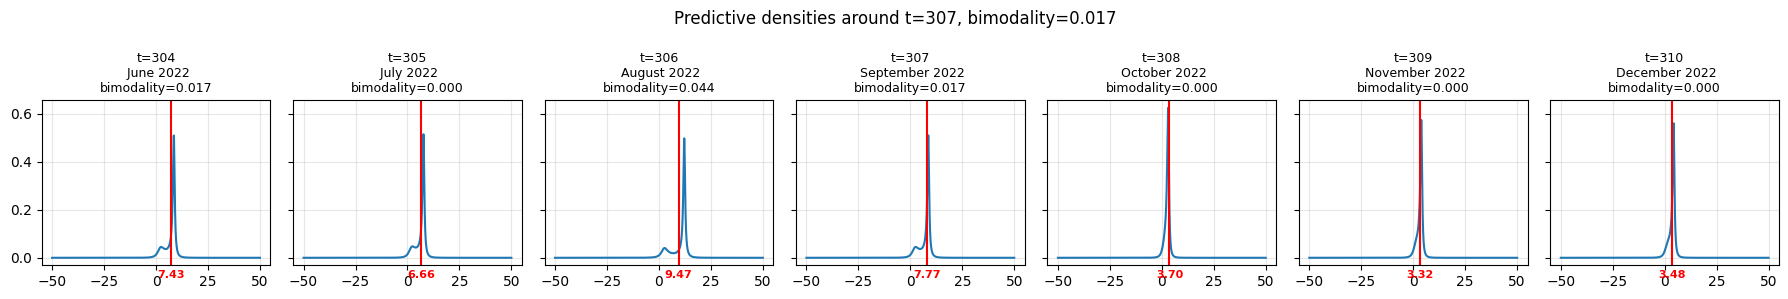

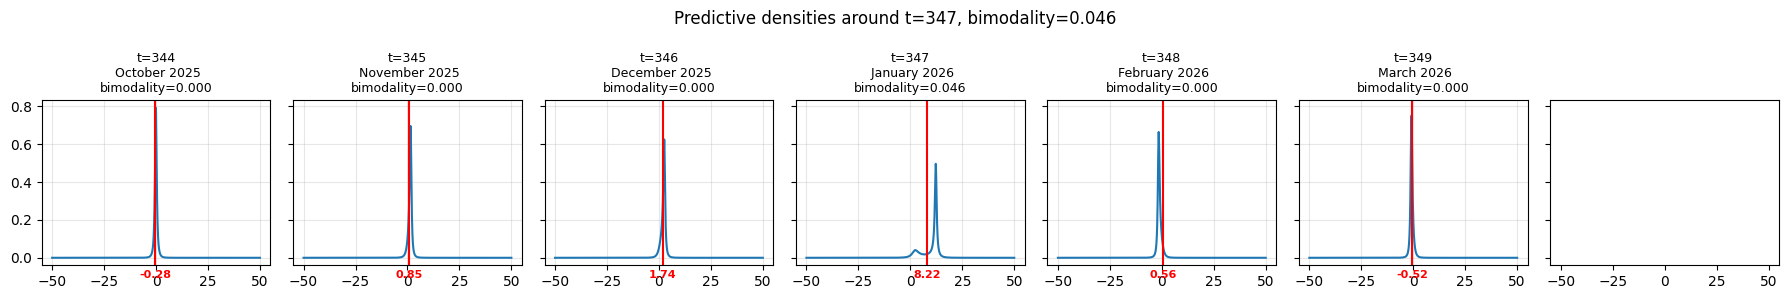

In [180]:
bimodal_times = np.asarray(times)[np.asarray(bimodality_series) != 0]

print("Bimodal times:")
print(bimodal_times)


grid = np.linspace(-50, 50, 3000)

window = 3

for t0 in bimodal_times:

    # Find where this time is located in the times array
    idx = np.where(times == t0)[0][0]

    idx_start = max(0, idx - window)
    idx_end   = min(len(times) - 1, idx + window)

    fig, axes = plt.subplots(1, 7, figsize=(18, 3), sharex=True, sharey=True)
    axes = np.ravel(axes)

    for ax, j in zip(axes, range(idx_start, idx_end + 1)):
        plot_predictive_density_simple(
            ax=ax,
            predictive_density_fn=marx_cauchy_pred_density,
            grid=grid,
            y=y,
            X=X,
            t=times[j],
            params=params,
            title=f"t={times[j]}\n {df.index[times[j]].strftime('%B %Y')}\nbimodality={bimodality_series[j]:.3f}",
        )

    plt.suptitle(
        f"Predictive densities around t={t0}, "
        f"bimodality={bimodality_series[idx]:.3f}"
    )
    plt.tight_layout()
    plt.show()

### Bimodality/ Predictive Density changes for different X values

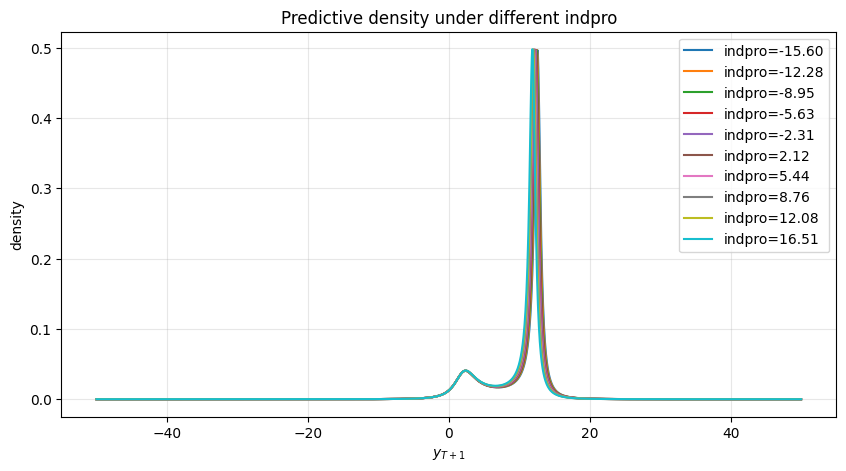

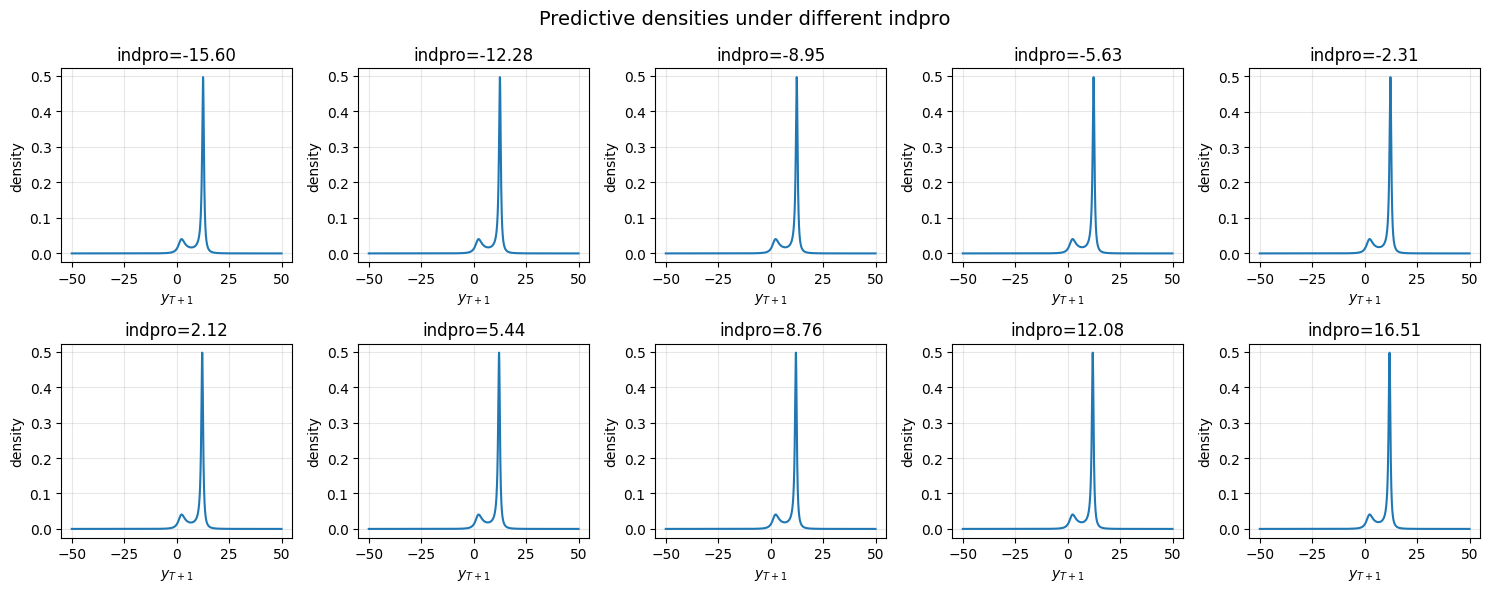

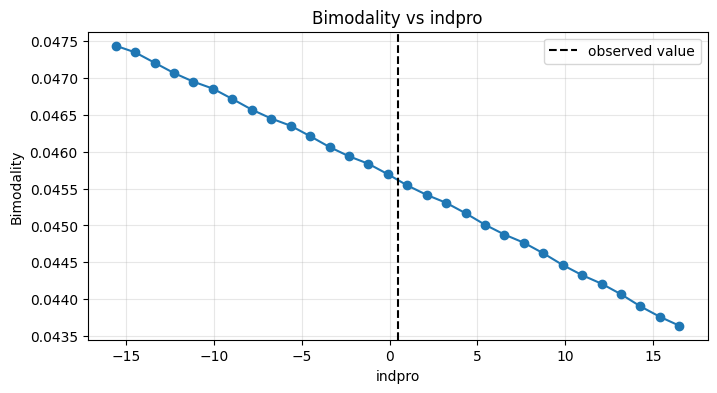

In [181]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -489.95525752865206

Estimated parameters:
phi             =     0.2242 (0.0351)
psi             =     0.7909 (0.0243)
sigma           =     0.5536 (0.0457)
nu              =     2.0100 (0.3009)

Hessian condition number:
191.91175103832245

Eigenvalues of Hessian:
[2097.06591048  753.08781079  884.53441133   10.92724077]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -489.955258
AIC:            987.910515
BIC:            1003.319325
R^2:            0.686057

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 11.928530, p-value = 0.000552808
    lag  5: statistic = 24.682376, p-value = 0.00016045
    lag 10: statistic = 35.121698, p-value = 0.000119032
    lag 20: statistic = 40.483838, p-value = 0.00433681

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: s

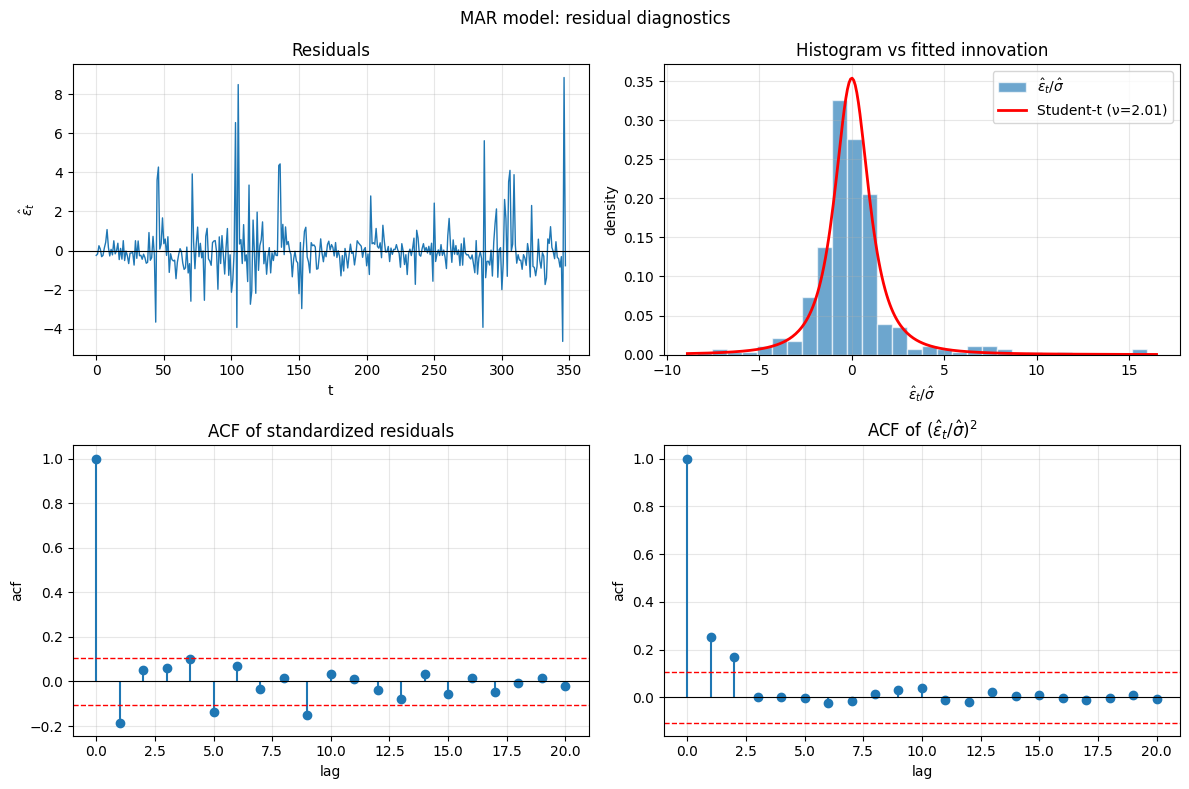

In [182]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

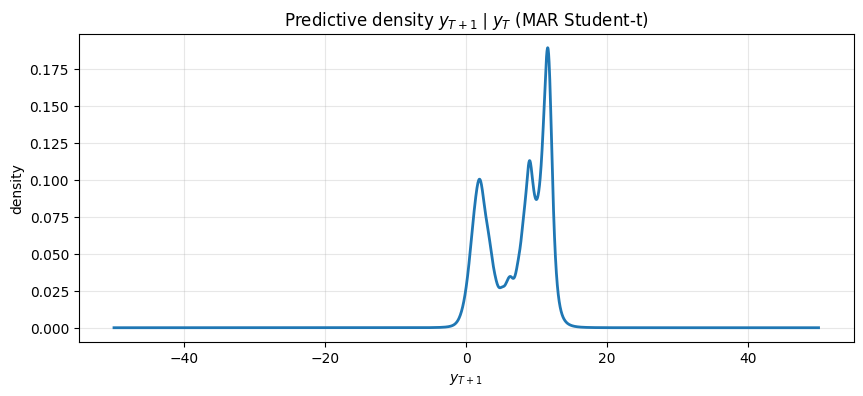

In [183]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

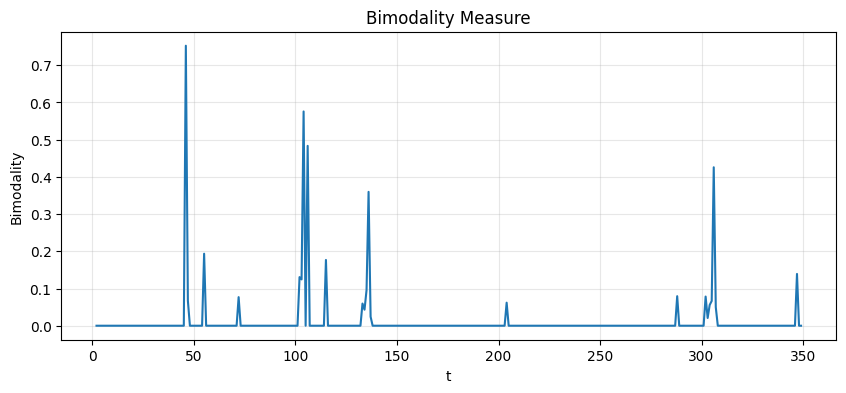

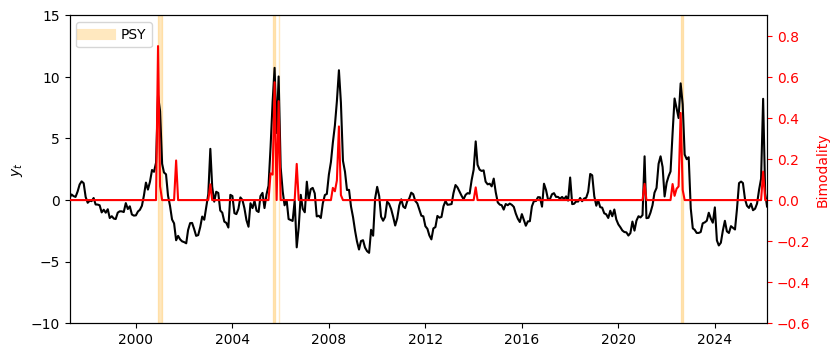

In [184]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -484.5727034220921

Estimated parameters:
phi             =     0.2288 (0.0379)
psi             =     0.7645 (0.0283)
beta_indpro     =     0.0205 (0.0090)
beta_hdd        =    -0.0221 (0.0091)
beta_sp500      =    -0.0192 (0.0138)
sigma           =     0.5408 (0.0483)
nu              =     2.0100 (0.3246)

Hessian condition number:
3145.484601312413

Eigenvalues of Hessian:
[2.95075122e+04 1.35016089e+04 4.75564173e+03 1.72569888e+03
 6.11016018e+02 8.82903845e+02 9.38091135e+00]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -484.572703
AIC:            983.145407
BIC:            1010.110824
R^2:            0.686434

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 10.497319, p-value = 0.00119548
    lag  5: statistic = 23.263280, p-value = 0.000300602
    lag 10: statistic = 33.589268, p-value = 0.000216732
    lag 20: statistic = 38.65

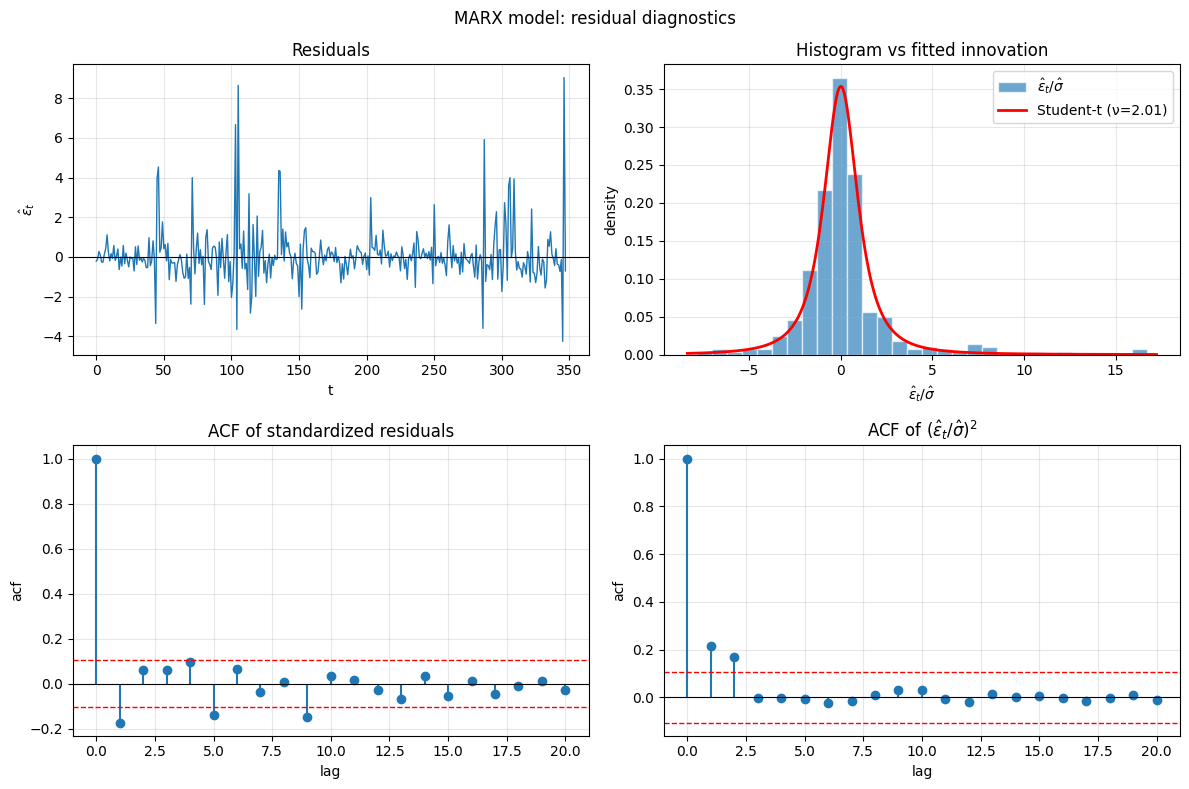

In [185]:
param_names = [ "phi", "psi", "beta_indpro", "beta_hdd", "beta_sp500", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None), 
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

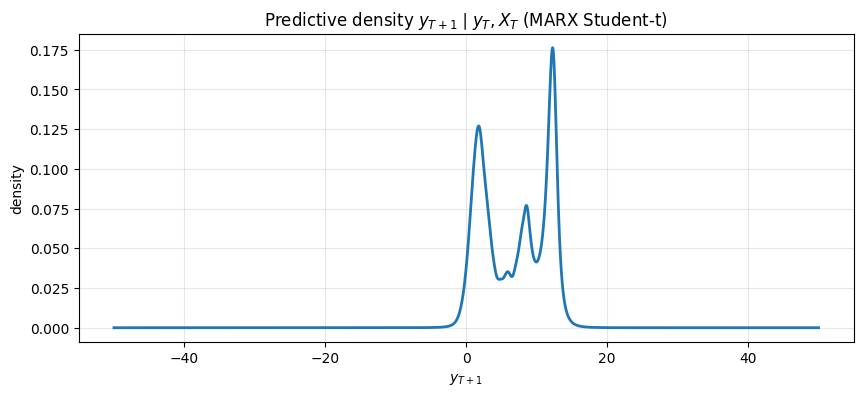

In [186]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

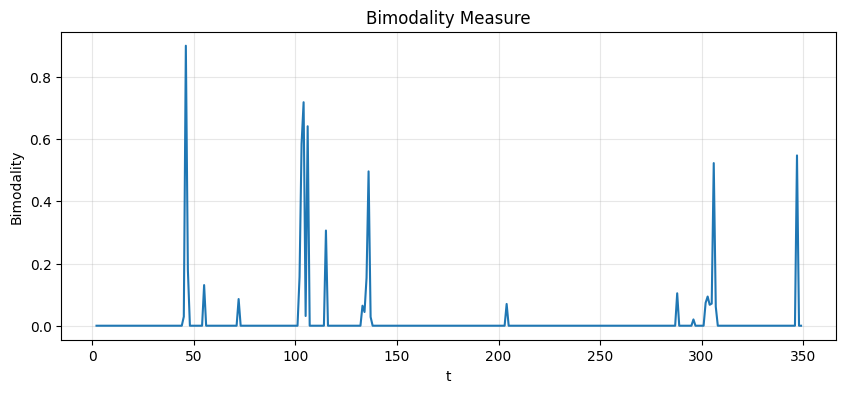

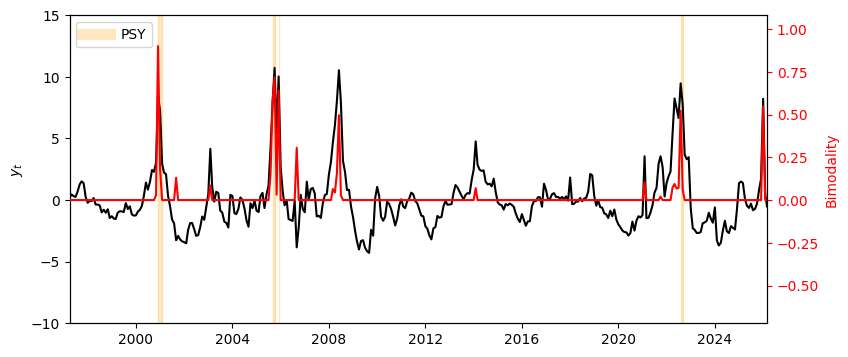

In [187]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

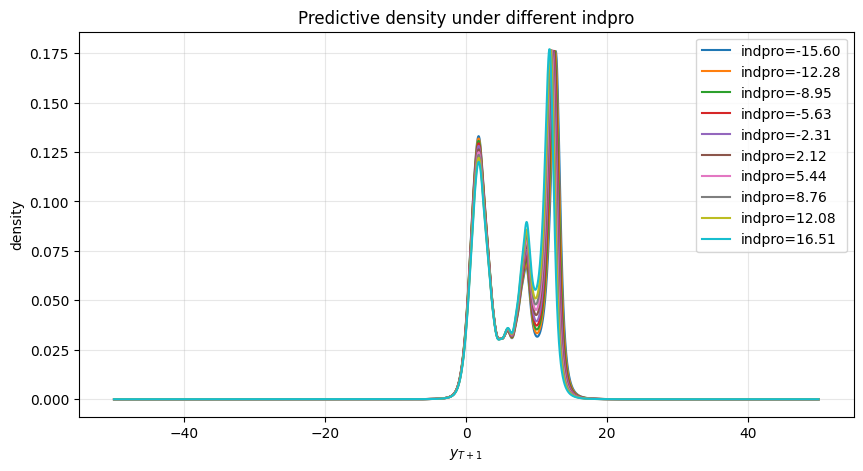

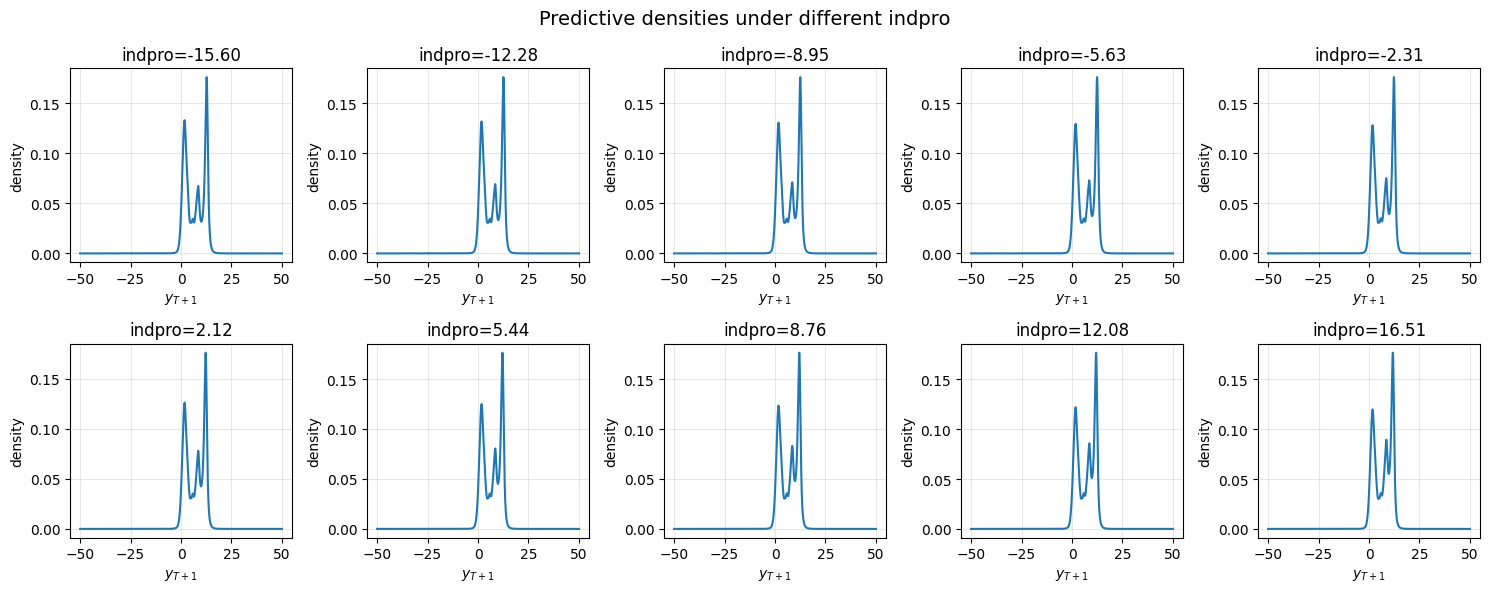

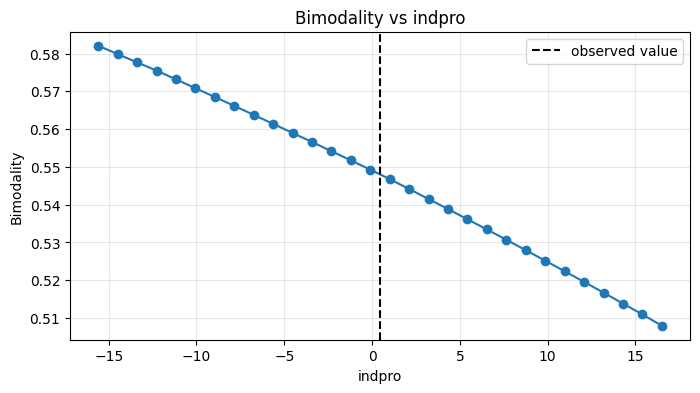

In [188]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)
